## 1. Loading the data
Loaded the raw file with `load_data()` function. It comes in as 6 columns, and each row is the noise level at one frequency for one wind-tunnel test.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent / "src"))
from airfoil.data import load_data

df = load_data() # Reads my file and returns the data as a pandas DataFrame
df.head()        # Show the first 5 rows

,frequency_hz,alpha_deg,chord_m,velocity_ms,delta_star_m,spl_db
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


## 2. Checking the ranges
All 1503 rows are there for every column, and the min/max values match what the UCI page says, so the file loaded correctly.

The noise level (SPL) goes from about 103 to 141 dB. Its standard deviation is 6.9 dB. Hence, if a model just predicted the average 124.8 dB every time, it would be off by about 6.9 dB on average, so my models need to do clearly better than that to be useful.

Noticed frequency and delta star have means much bigger than their medians, which means most values are small with a few very large ones. Delta star covers about a 146× range, so that means I'll probably need a log transform.

In [2]:
df.describe() # Built in function for pandas, computes the data summary statistics

,frequency_hz,alpha_deg,chord_m,velocity_ms,delta_star_m,spl_db
count,1503.000000,1503.000000,1503.000000,1503.000000,1503.000000,1503.000000
mean,2886.380572,6.782302,0.136548,50.860745,0.011140,124.835943
std,3152.573137,5.918128,0.093541,15.572784,0.013150,6.898657
min,200.000000,0.000000,0.025400,31.700000,0.000401,103.380000
25%,800.000000,2.000000,0.050800,39.600000,0.002535,120.191000
50%,1600.000000,5.400000,0.101600,39.600000,0.004957,125.721000
75%,4000.000000,9.900000,0.228600,71.300000,0.015576,129.995500
max,20000.000000,22.200000,0.304800,71.300000,0.058411,140.987000


## 3. Missing values
Every column shows 0, that means nothing is missing. Proof that it don't need to fill in or drop any rows.

In [3]:
df.isna().sum()
# Count missing values (NaN) in each column
# .isna means go through every single value in the table
# Mark it "TRUE" if missing or not a number
# Mark it "False" if it has a value
# .sum means count True as 1, False as 0
# Total is number of missing value in that column

frequency_hz    0
alpha_deg       0
chord_m         0
velocity_ms     0
delta_star_m    0
spl_db          0
dtype: int64

## 4. Duplicates
No repeated rows, that means every row is a separate measurement.

In [4]:
df.duplicated().sum() #Check any repeated row

np.int64(0)

## 5. How many different values each column has
This was more revealing than I expected. Frequency has 21 values (the standard third-octave bands), but chord has only 6 and velocity only 4. Hence, the whole dataset comes from a handful of test conditions, whereby each measured across lots of frequencies.

Angle of attack has 27 different values between 0 deg and 22.2 deg, even though the UCI page lists it as "Binary". That label is wrong, so it's a good reminder to check the data myself rather than trust the metadata.

In [5]:
df.nunique() 
# In the entire dataset, it have 1503 rows of data, this function is to check how many same number in each column have

frequency_hz      21
alpha_deg         27
chord_m            6
velocity_ms        4
delta_star_m     105
spl_db          1456
dtype: int64

## 6. Counting the test set-ups
Grouping by chord, velocity and angle gives 106 separate wind tunnel tests. That's about 14 rows per test, but there are 21 frequency bands, so not every test was measured at every frequency.

*Findings*: rows from the same test are very similar to each
other. If I split the data randomly, the model would be tested on data almost identical to what it trained on and look better than it reallyis. So I'll need to keep whole tests together when validating.

In [6]:
df.groupby(["chord_m", "velocity_ms", "alpha_deg"]).ngroups
# Chord, velocity & alpha will be the fix variable while it will tested by different frequency
# These three variable with the same value will group together
# There are total of 106 different groups based on the 1503 rows

106

## 7. Is delta star a separate measurement?
Every test has exactly one delta star value, so once you know the chord, velocity and angle, delta star is fixed. That tells me it was calculated from the test conditions, not measured on its own. (There are 105 delta star values for 106 tests, so two tests just happen to share the same value.)

This matters because someone using my model can't just pick any delta star. They'd need to work it out from the other three inputs.

In [7]:
df.groupby(["chord_m", "velocity_ms", "alpha_deg"])["delta_star_m"].nunique().max()
# ["delta_star_m"] looks only at the delta star column inside each pile.
# .nunique() counts for each pile, how many different delta star values it contains.
# Will get one number per set-up.
# .max() takes the largest of those numbers, giving one final answer for the whole dataset.

np.int64(1)

## 8. Looking at the distributions
- Frequency and delta star are heavily bunched at the low end with a long tail, which backs up using a log transform.

- Chord and velocity are just a few spikes because they were fixed test settings. The coverage isn't even either: 39.6 m/s and 71.3 m/s have about 470 rows each, but 31.7 m/s and 55.5 m/s only about 280.

- Around 330 rows are at 0 deg angle of attack, which tells that it is the most common setting.

- SPL looks roughly bell-shaped, centred around 125 dB.

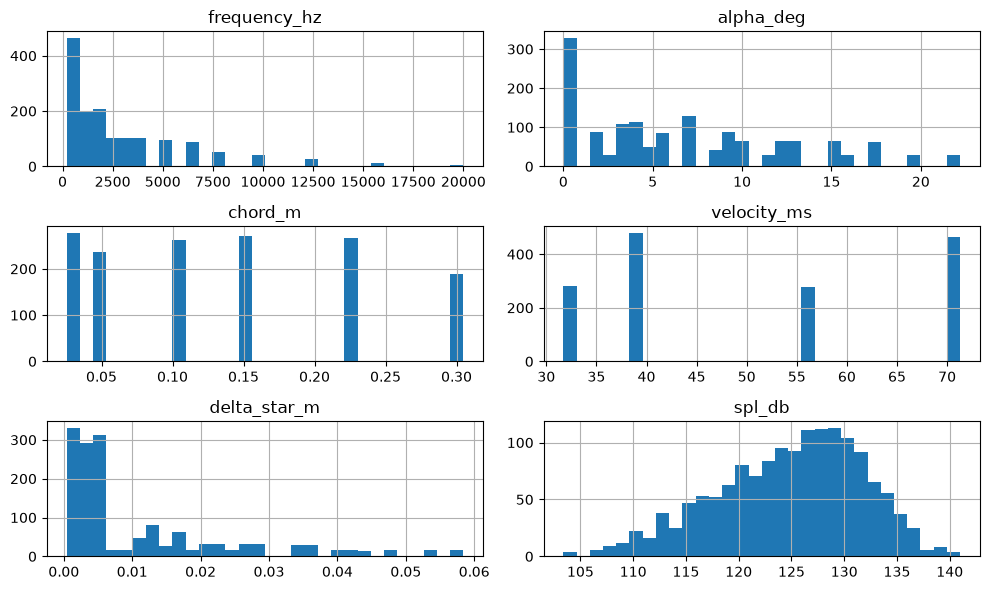

In [8]:
df.hist(figsize=(10,6), bins = 30)
# 10 wide 6 tall, bins=30 means split each column range into 30 equal width bars
plt.tight_layout()
plt.savefig("../results/histograms.png", dpi = 150)
# dpi = figsize * dpi, higher dpi higher pixel, more clear
plt.show()

In [9]:
# Exact number of rows for each velocity and chord setting
print(df["velocity_ms"].value_counts().sort_index())
print()
print(df["chord_m"].value_counts().sort_index())

velocity_ms
31.7    281
39.6    480
55.5    277
71.3    465
Name: count, dtype: int64

chord_m
0.0254    278
0.0508    237
0.1016    263
0.1524    271
0.2286    266
0.3048    188
Name: count, dtype: int64
